# PERSONAL BANKING FINANCIAL ANALYSIS - SYNTHETIC DATA VERSION

This notebook analyzes personal banking financial data to identify spending patterns, income trends, recurring expenses, and opportunities for improved financial management.

## Import Packages

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from dash import Dash, html, dcc, callback, Output, Input
import pdfplumber
import os
import re
from thefuzz import fuzz, process
import ollama
import json
import subprocess


## Constants

In [65]:
dir_path = "..\\synthetic-data\\" # Path to retrieve data from
llm = "llama3.2:3b" # LLM to use for semantic summarization
json_dir_path = "..\\json-dumps\\" # Directory to write json files
json_file_round_1 = 'description_map_round_1.json' # Filename for first json file
json_file_round_2 = 'description_map_round_2.json' # Filename for second json file

## Loading Data

Get all files from the specified directory. All files are expected to be PDFs.

In [66]:
files = os.listdir(dir_path)
files = [file for file in files if file.find('.pdf') != -1] # Only keep filenames for PDFs

print("Number of files in directory:", len(files))

Number of files in directory: 48


The expected filename format is `statement_MM_YYYY.pdf` where `MM` is the two digit representation of the month and `YYYY` is the four digit representation of the year.

Sorting will be done by year then month, both in ascending order.

Split by '\_' then '.' to get year.<br> 
Split by '\_' to get month.

In [67]:
files.sort(key=lambda fname: (fname.split('_')[-1].split('.')[0],
                              fname.split('_')[1]))

print(f"Files sorted by year then month in ascending order:\n{files}")

Files sorted by year then month in ascending order:
['statement_08_2022.pdf', 'statement_09_2022.pdf', 'statement_10_2022.pdf', 'statement_11_2022.pdf', 'statement_12_2022.pdf', 'statement_01_2023.pdf', 'statement_02_2023.pdf', 'statement_03_2023.pdf', 'statement_04_2023.pdf', 'statement_05_2023.pdf', 'statement_06_2023.pdf', 'statement_07_2023.pdf', 'statement_08_2023.pdf', 'statement_09_2023.pdf', 'statement_10_2023.pdf', 'statement_11_2023.pdf', 'statement_12_2023.pdf', 'statement_01_2024.pdf', 'statement_02_2024.pdf', 'statement_03_2024.pdf', 'statement_04_2024.pdf', 'statement_05_2024.pdf', 'statement_06_2024.pdf', 'statement_07_2024.pdf', 'statement_08_2024.pdf', 'statement_09_2024.pdf', 'statement_10_2024.pdf', 'statement_11_2024.pdf', 'statement_12_2024.pdf', 'statement_01_2025.pdf', 'statement_02_2025.pdf', 'statement_03_2025.pdf', 'statement_04_2025.pdf', 'statement_05_2025.pdf', 'statement_06_2025.pdf', 'statement_07_2025.pdf', 'statement_08_2025.pdf', 'statement_09_2025.pdf

Important note: Each page in each PDF should have three tables:
1. Header table with Branch number, Account number, Page number and Tax ID.
2. Statement table with transactons
3. Footer table with summary information: Starting balance, Debits count and amount; Credit count and amount, Closing balance.

Some PDFs have issues where either:
1. A blank page as the last page with no statement table
2. The last page has the Header table but no Statement table

Any pages with these issues are ignored.

In [68]:
df = pd.DataFrame()

for filename in files:
    tables = list()
    file_path = dir_path + filename

    # Grab statement year from filename
    year = filename.split('_')[-1].split('.')[0]

    with pdfplumber.open(file_path) as pdf:
        num_pages = len(pdf.pages) # Store number of pages extracted

        try:
            for pg in pdf.pages:
                # Usually three tables per page, take the second table only
                # If there are not three tables, do not use that page
                if len(pg.extract_tables()) != 3:
                    num_pages-=1
                else:
                    table = pg.extract_tables()[1] 
                    tables.append(table)

            if len(tables) != num_pages:
                raise ValueError('Number of tables extracted doesn\'t match the number of pages')

        except ValueError as e:
            print("Error:", e)

    cols = tables[0][0]

    for tbl in tables:
        # Take second record (third row) to last record in each table
        # First record is Balance Forward which is not needed
        tmp_df = pd.DataFrame(tbl[2:-1], columns=cols)
        tmp_df['Year'] = int(year)

        df = pd.concat([df, tmp_df],
                    ignore_index=True)
        
print("All data loaded into dataframe")       

All data loaded into dataframe


## Data Wrangling

In [69]:
df.isnull().sum().sum()

0

In [70]:
df.head()

,DATE,DESCRIPTION,DEBITS,CREDITS,BALANCE,Year
0,AUG02,EMPLOYER PAYROLL,0.00,3680.00,10412.28,2022
1,AUG02,ESSO BLACK ROCK,71.93,0.00,10340.35,2022
2,AUG06,NETFLIX*MONTHLY,31.99,0.00,10308.36,2022
3,AUG06,2.00% Exchange Tax,0.64,0.00,10307.72,2022
4,AUG06,MAS STORES 1048,141.96,0.00,10165.76,2022


In [71]:
df.dtypes

DATE           object
DESCRIPTION    object
DEBITS         object
CREDITS        object
BALANCE        object
Year            int64
dtype: object

Change all columns to titlecase

In [72]:
df.columns = [col.title() for col in df.columns]
df.columns

Index(['Date', 'Description', 'Debits', 'Credits', 'Balance', 'Year'], dtype='object')

### Cast currency columns to float

Remove commas from columns representing currency then cast type to float

In [73]:
df[['Debits','Credits','Balance']] = df[['Debits','Credits','Balance']].replace(',', '', regex=True)
df[['Debits','Credits','Balance']] = df[['Debits','Credits','Balance']].astype(float)
df[['Debits','Credits','Balance']].dtypes

Debits     float64
Credits    float64
Balance    float64
dtype: object

### Create datetime column

In [74]:
df_date = df[['Year', 'Date']].copy()
df_date.head()

,Year,Date
0,2022,AUG02
1,2022,AUG02
2,2022,AUG06
3,2022,AUG06
4,2022,AUG06


Get each component necessary (year, month, day) to create a datetime value for each record.

Year is already separated. 

Split `Date` into `Month_Short` and `Day`.<br>
Example: AUG10 (`Date`) -> AUG (`Month_Short`) and 10 (`Day`)

Map `Month_Short` to the number representations and create `Month`.<br>
Example: AUG (`Month_Short`) -> 8 (`Month`)

Use `Year`, `Month` and `Day` to create a datetime column.

In [75]:
df_date['Month_Short'] = df_date['Date'].str[0:3]
df_date['Day'] = df_date['Date'].str[3:]

month_map = {
    'JAN': 1,
    'FEB': 2,
    'MAR': 3,
    'APR': 4,
    'MAY': 5,
    'JUN': 6,
    'JUL': 7,
    'AUG': 8,
    'SEP': 9,
    'OCT': 10,
    'NOV': 11,
    'DEC': 12
}

df_date['Month'] = df_date['Month_Short'].map(month_map)
df['FullDate'] = pd.to_datetime(df_date[['Year', 'Month','Day']])

df[['Date', 'Year', 'FullDate']].head()

,Date,Year,FullDate
0,AUG02,2022,2022-08-02
1,AUG02,2022,2022-08-02
2,AUG06,2022,2022-08-06
3,AUG06,2022,2022-08-06
4,AUG06,2022,2022-08-06


### Remove date text from Description column

Some descriptions for transactions have the month and day appended. This information is redundant.

Use regular expression to find any month abbrevations with one or more digits trailing that represent the day (Example: APR02). If a match is found, return the start of the string up to before the month and day (remove the date text). Remove any trailing spaces (and leading spaces for good measure) left after transformation. If no match is found then return original string.

The presence of digits (1 or more) after the abbreviated month name is important in the regular expression because the month abbreviations can match with non-date text. In some cases previously, values in Description became empty strings because the match was found at the start of the string so the string indexing removed all text.

In [76]:
def removeDateFromDescrip(text):
    pattern = "\d+|".join(month_map.keys())
    match = re.search(pattern, text)

    if match:
        return text[:match.start()].strip()
    else: 
        return text

In [77]:
try:
    df['Description_Trim'] = df['Description'].apply(removeDateFromDescrip)

    if len(df[df['Description_Trim'] == '']) != 0:
        raise ValueError('Transformation left empty values in Description column')

except ValueError as e:
    print("Error:", e)

else:
    print('Description transformation succeeded')

df[['Description','Description_Trim']].head()

Description transformation succeeded


,Description,Description_Trim
0,EMPLOYER PAYROLL,EMPLOYER PAYROLL
1,ESSO BLACK ROCK,ESSO BLACK ROCK
2,NETFLIX*MONTHLY,NETFLIX*MONTHLY
3,2.00% Exchange Tax,2.00% Exchange Tax
4,MAS STORES 1048,MAS STORES 1048


### First Round - Fuzzy String Matching

The data has many transactions that are from the same entity but the strings might be slighty different so it becomes difficult to group for analysis and visualisation.

Some reasons for variations:
- Unique numbers are appended that relate to the transaction
- The statement descriptor for an entity may have changed
- The entity's name is different now after changing the payee's name
- Transactions were completed with different subsidiaries under the same parent company so similar but slightly different statement descriptors are shown

Fuzzy matching will help to match close terms.<br><br>

Firstly, remove newline characters from trimmed descriptions and remove any numbers at end of string with a preceding space.

Some transactions have long descriptions with newline characters or long, unique numbers appended at the end.

In [78]:
df['Description_Trim'] = df['Description_Trim'].replace('\\n', '', regex=True)
df['Description_Trim'] = df['Description_Trim'].apply(lambda x: x[:match.start()].strip() if(match := re.search("\w\d+$", x)) else x)

Since an LLM is being used to summarize each set of fuzzy string matches, let's save the mapping created using the fuzzy string matches and semantic summaries. It is saved as a json file. This will make the workflow more deterministic instead of the LLM creating new summaries each run of this notebook.

If the mapping exists as a json file then skip the call to the LLM to make summaries. The fuzzy string matching will be skipped too despite it being deterministic. If the LLM is not being called then the fuzzy string matching is not needed.

If the mapping does not exist as a json file then run the fuzzy string matching and call the LLM to create summaries.

In [79]:
json_file_path = f'{json_dir_path}{json_file_round_1}'
json_file_exists_flag = False

if os.path.isfile(json_file_path):
    with open(json_file_path, 'r') as fp:
        imported_descrip_map = json.load(fp)
        json_file_exists_flag = True

    print(f'{json_file_round_1} exists. Decription map imported.')
    print(imported_descrip_map)

else:
    print(f'{json_file_round_1} does not exists. Decription map will be created.')

description_map_round_1.json exists. Decription map imported.
{'EMPLOYER PAYROLL': 'Employer', 'ESSO BLACK ROCK': 'Esso', 'NETFLIX*MONTHLY': 'Netflix', 'NETFLIX.COM': 'Netflix', '2.00% Exchange Tax': 'Exchange Tax', 'MAS STORES 1048': 'MAS', 'MAS STORES': 'MAS', 'OISTINS FISH FRY': 'Oistins', 'RENT PAYMENT': 'Rent', 'BARBADOS LIGHT & POWER': 'BARBADOS LIGHT & POWER', 'TRIMART SUPERMARKET': 'Trimart', 'SOL TOP ROCK': 'SOL Top Rock', 'CHEFETTE ROCKLEY': 'Chefette Rockley', 'SURFERS BAY GYM': 'Surfers Bay Gym', 'KFC BARBADOS 021': 'KFC', 'KFC BARBADOS': 'KFC', 'FLOW INTERNET': 'Flow', 'BURGER KING WARRENS': 'Burger King', 'BARBADOS WATER AUTHORITY': 'Barbados Water Authority', 'DIGICEL POSTPAID': 'Digicel', 'MASSY STORES SUPERCENTRE': 'Massy Stores', 'SOL WILDEY': 'SOL WILDEY', 'ZR VAN FARE': 'Zara', 'COFFEE BEAN WORTHING': "Worth's Coffee", 'ROUTE TAXI FARE': 'Taxi', 'CAFE 195 & BISTRO': 'Cafe', 'COST-U-LESS WARRENS': 'Cost-U-LESS', 'WORTHING PARKING': 'Worth Parking', 'STEPHANIE KING': 

Get unique transformed Descriptions. Loop through each description. If this description was already matched using fuzzy string matching then skip this description.

Select the top 150 matches using three different fuzzy string matching functions. I tried multiple fuzzy string matching functions and no one function captured all that I wanted so I will use multiple for now and improve on this later.

Store all 450 matches in a list. Each match is a tuple containing the string and similarity score. Filter list and only keep matches with similarity score >= 90.

The threshold is high to avoid false positives. Then a second round of matching will be done later to capture anything missed.

Add these matches to a set to remove duplicates since multiple fuzzy string matching functions are being used. Only the string is added to the set. Add each set to a list that stores all fuzzy matches for each description.

In [80]:
if json_file_exists_flag == False:
    unique_descrips = df['Description_Trim'].unique().tolist()
    all_fuzzy_matches = list()

    loopcount = 0

    for descrip in unique_descrips:
        skip_item = False

        for fuzz_matches in all_fuzzy_matches:        
                if descrip in fuzz_matches:
                    skip_item = True
                    break

        if skip_item == True:
            continue

        fuzzy_set = set()
        filter_list = list()

        filter_list.extend(process.extract(descrip, unique_descrips,
                        scorer=fuzz.ratio, limit=150))

        filter_list.extend(process.extract(descrip, unique_descrips,
                        scorer=fuzz.partial_ratio, limit=150))

        filter_list.extend(process.extract(descrip, unique_descrips,
                        scorer=fuzz.token_sort_ratio, limit=150))

        # If similarity score greater than or equal to threshold then keep string
        filter_list = [item[0] for item in filter_list if item[1] >= 90]

        fuzzy_set.update(filter_list)

        all_fuzzy_matches.append(fuzzy_set)

        loopcount+=1

    print('First round of fuzzy string matching completed.')
    print('Loop count:', loopcount)
    print(all_fuzzy_matches)

else:
    print('First round of fuzzy string matching skipped because decription map imported.')

First round of fuzzy string matching skipped because decription map imported.


### First Round - Semantic Summarization with LLM

System prompt for LLM for summarization task

In [81]:
system_instruction_summarization = """
You are a text normalization assistant.

Your task is to summarize a group of semantically similar transaction descriptions into one concise, human-readable name.

The descriptions have already been grouped using fuzzy matching, so assume that they refer to the same merchant, service, organization, or transaction source.

Rules:

* Identify the common merchant, service, organization, or source represented by the descriptions.
* Return a concise name using 1 to 4 words.
* Prefer the recognizable merchant or organization name over transaction-specific details.
* Remove transaction IDs, reference numbers, dates, locations, phone numbers, URLs, and other irrelevant details.
* Preserve the recognizable brand or organization name when one is apparent.
* Do not invent information that is not reasonably supported by the descriptions.
* If the descriptions contain a person's name rather than a business, summarize using the person's name.
* Do not provide explanations, reasoning, punctuation, quotation marks, or additional text.
* Return only the summarized name.

Example:

Input:
NETFLIX.COM
NETFLIX.COM 800-123456
Netflix.com Amsterdam
NETFLIX MONTHLY

Output:
Netflix

Example:

Input:
WALMART #1234
WAL-MART POS 1234
Walmart Bridgetown
WALMART STORE

Output:
Walmart

Example:

Input:
SPOTIFY AB STOCKHOLM
Spotify Premium
SPOTIFY.COM

Output:
Spotify

"""

Start Ollama server

In [82]:
ollama_server = subprocess.Popen(["ollama","serve"])
print(f'Ollama is running. Process ID: {ollama_server.pid}')

Ollama is running. Process ID: 26772


Check if LLM is downloaded locally. If not, then download it.

In [83]:
models_list = [mdl.model for mdl in ollama.list().models]

if llm not in models_list:
    ollama.pull(llm)
    print('LLM downloaded.\n')
else:
    print('LLM already installed.\n')

print('Model list:')
for mdl in models_list:
    print(mdl)

LLM already installed.

Model list:
llama3.2:3b
llama3.2:1b
deepseek-r1:7b
deepseek-r1:1.5b
deepseek-r1:8b
nomic-embed-text:latest
llama3.1:latest


Loop through each set of fuzzy string matches. Concatenate all strings into a single string and pass to an LLM for a summary.

Using LLama3.2 3B for now since it is lightweight.

Create dictionary that maps fuzzy matches to summary. This will be used to replace values in dataframe with summaries.

Dictionary structure:<br> 
`{`<br> 
    `string_1_from_fuzzy_set_1 : summary_1,`<br> 
    `...`<br> 
   ` string_m_from_fuzzy_set_1 : summary_1,`<br> 
    `string_1_from_fuzzy_set_2 : summary_2,`<br> 
    `...`<br> 
    `string_n_from_fuzzy_set_2 : summary_2,`<br>
    `...`<br>  
`}`

Store dictionary as a json file for future use.


In [84]:
if json_file_exists_flag == False:

    descrip_map = dict()

    for fuzzies in all_fuzzy_matches:
        strings_list = [fuzzy for fuzzy in fuzzies]
        strings = ", ".join(strings_list)

        response = ollama.chat(
            model=llm,
            messages=[
                {
                    "role":'system',
                    "content": system_instruction_summarization

                },
                {
                    "role": "user",
                    "content": "Transaction descriptions: " + strings
                }
            ]
        )

        descrip_map.update({string:response.message.content.strip() for string in strings_list})

    with open(json_file_path, 'w') as fp:
        json.dump(descrip_map, fp, indent=4)

    print('First decription map written to file.')

else:
    descrip_map = imported_descrip_map
    print('Imported first decription map.')

descrip_map

Imported first decription map.


{'EMPLOYER PAYROLL': 'Employer',
 'ESSO BLACK ROCK': 'Esso',
 'NETFLIX*MONTHLY': 'Netflix',
 'NETFLIX.COM': 'Netflix',
 '2.00% Exchange Tax': 'Exchange Tax',
 'MAS STORES 1048': 'MAS',
 'MAS STORES': 'MAS',
 'OISTINS FISH FRY': 'Oistins',
 'RENT PAYMENT': 'Rent',
 'BARBADOS LIGHT & POWER': 'BARBADOS LIGHT & POWER',
 'TRIMART SUPERMARKET': 'Trimart',
 'SOL TOP ROCK': 'SOL Top Rock',
 'CHEFETTE ROCKLEY': 'Chefette Rockley',
 'SURFERS BAY GYM': 'Surfers Bay Gym',
 'KFC BARBADOS 021': 'KFC',
 'KFC BARBADOS': 'KFC',
 'FLOW INTERNET': 'Flow',
 'BURGER KING WARRENS': 'Burger King',
 'BARBADOS WATER AUTHORITY': 'Barbados Water Authority',
 'DIGICEL POSTPAID': 'Digicel',
 'MASSY STORES SUPERCENTRE': 'Massy Stores',
 'SOL WILDEY': 'SOL WILDEY',
 'ZR VAN FARE': 'Zara',
 'COFFEE BEAN WORTHING': "Worth's Coffee",
 'ROUTE TAXI FARE': 'Taxi',
 'CAFE 195 & BISTRO': 'Cafe',
 'COST-U-LESS WARRENS': 'Cost-U-LESS',
 'WORTHING PARKING': 'Worth Parking',
 'STEPHANIE KING': 'Stephanie King',
 'IMART PHARMACY

Map decription values with dictionary created with fuzzy string matches and summaries.

In [85]:
df['Description_Trim'] = df['Description_Trim'].map(descrip_map)
df['Description_Trim']

0              Employer
1                  Esso
2               Netflix
3          Exchange Tax
4                   MAS
             ...       
2187                ATM
2188        Nicole Best
2189                MAS
2190    Danielle Holder
2191            Oistins
Name: Description_Trim, Length: 2192, dtype: object

### Second Round - Fuzzy String Matching

Save the mapping for this second round also.

If the mapping exists as a json file then skip the call to the LLM to make summaries. The fuzzy string matching will be skipped too.

If the mapping does not exist as a json file then run the fuzzy string matching and call the LLM to create summaries.

In [86]:
json_file_path_2 = f'{json_dir_path}{json_file_round_2}'
json_file_2_exists_flag = False

if os.path.isfile(json_file_path_2):
    with open(json_file_path_2, 'r') as fp:
        imported_descrip_map = json.load(fp)
        json_file_2_exists_flag = True

    print(f'{json_file_round_2} exists. Decription map imported.')
    print(imported_descrip_map)

else:
    print(f'{json_file_round_2} does not exists. Decription map will be created.')

description_map_round_2.json exists. Decription map imported.
{'Employer': 'Employer', 'Esso': 'Esso', 'Netflix': 'Netflix', 'Exchange Tax': 'Exchange Tax', 'MAS': 'MAS', 'Oistins': 'Oistins', 'Rent': 'Rent', 'BARBADOS LIGHT & POWER': 'BARBADOS LIGHT & POWER', 'Trimart': 'Trimart', 'SOL Top Rock': 'SOL Top Rock', 'Chefette Rockley': 'Chefette Rockley', 'Surfers Bay Gym': 'Surfers Bay Gym', 'KFC': 'KFC', 'Flow': 'Flow', 'Burger King': 'Burger King', 'Barbados Water Authority': 'Barbados Water Authority', 'Digicel': 'Digicel', 'Massy Stores': 'Massy Stores', 'SOL WILDEY': 'SOL Wildey', 'Zara': 'Zara', "Worth's Coffee": "Worth's Coffee", 'Taxi': 'Taxi', 'Cafe': 'Cafe', 'Cost-U-LESS': 'Cost-U-LESS', 'Worth Parking': 'Worth Parking', 'Stephanie King': 'Stephanie King', 'IMart Pharmacy': 'IMart', "Rubi's": "Rubi's", 'Jason Williams': 'Jason Williams', 'SHEIN': 'SHEIN', 'Kensington': 'Kensington', 'Payroll Credit': 'Payroll Credit', 'DO IT BEST BARBADOS': 'DO IT BEST BARBADOS', 'Massy': 'Mass

Use only the token ratio function for this round. Lowered threshold slightly because the descriptions are less messy.

In [87]:
if json_file_2_exists_flag == False:
    unique_descrips = df['Description_Trim'].unique()
    all_fuzzy_matches = list()

    loopcount = 0

    for descrip in unique_descrips:
        skip_item = False

        for fuzz_matches in all_fuzzy_matches:        
                if descrip in fuzz_matches:
                    skip_item = True
                    break

        if skip_item == True:
            continue

        fuzzy_set = set()
        filter_list = list()

        filter_list.extend(process.extract(descrip, unique_descrips,
                        scorer=fuzz.token_sort_ratio, limit=50))

        # If similarity score greater than or equal to threshold then keep string
        filter_list = [item[0] for item in filter_list if item[1] >= 85]

        fuzzy_set.update(filter_list)

        all_fuzzy_matches.append(fuzzy_set)

        loopcount+=1

    print('Second round of fuzzy string matching completed.')
    print('Loop count:', loopcount)
    print(all_fuzzy_matches)

else:
    print('Second round of fuzzy string matching skipped because decription map imported.')


Second round of fuzzy string matching skipped because decription map imported.


### Second Round - Semantic Summarization with LLM

Same LLM call as before but with the less messy descriptions.

In [88]:
if json_file_2_exists_flag == False:

    descrip_map = dict()

    for fuzzies in all_fuzzy_matches:
        strings_list = [fuzzy for fuzzy in fuzzies]
        strings = ", ".join(strings_list)

        response = ollama.chat(
            model=llm,
            messages=[
                {
                    "role":'system',
                    "content": system_instruction_summarization

                },
                {
                    "role": "user",
                    "content": "Transaction descriptions: " + strings
                }
            ]
        )

        descrip_map.update({string:response.message.content.strip() for string in strings_list})

    with open(json_file_path_2, 'w') as fp:
        json.dump(descrip_map, fp, indent=4)

    print('Second decription map written to file.')

else:
    descrip_map = imported_descrip_map
    print('Imported second decription map.')

descrip_map

Imported second decription map.


{'Employer': 'Employer',
 'Esso': 'Esso',
 'Netflix': 'Netflix',
 'Exchange Tax': 'Exchange Tax',
 'MAS': 'MAS',
 'Oistins': 'Oistins',
 'Rent': 'Rent',
 'BARBADOS LIGHT & POWER': 'BARBADOS LIGHT & POWER',
 'Trimart': 'Trimart',
 'SOL Top Rock': 'SOL Top Rock',
 'Chefette Rockley': 'Chefette Rockley',
 'Surfers Bay Gym': 'Surfers Bay Gym',
 'KFC': 'KFC',
 'Flow': 'Flow',
 'Burger King': 'Burger King',
 'Barbados Water Authority': 'Barbados Water Authority',
 'Digicel': 'Digicel',
 'Massy Stores': 'Massy Stores',
 'SOL WILDEY': 'SOL Wildey',
 'Zara': 'Zara',
 "Worth's Coffee": "Worth's Coffee",
 'Taxi': 'Taxi',
 'Cafe': 'Cafe',
 'Cost-U-LESS': 'Cost-U-LESS',
 'Worth Parking': 'Worth Parking',
 'Stephanie King': 'Stephanie King',
 'IMart Pharmacy': 'IMart',
 "Rubi's": "Rubi's",
 'Jason Williams': 'Jason Williams',
 'SHEIN': 'SHEIN',
 'Kensington': 'Kensington',
 'Payroll Credit': 'Payroll Credit',
 'DO IT BEST BARBADOS': 'DO IT BEST BARBADOS',
 'Massy': 'Massy',
 'Grillin': 'Grillin',
 '

Stop the ollama server.

In [89]:
ollama_server.terminate()

Map description values with new dictionary.

In [90]:
df['Description_Trim'] = df['Description_Trim'].map(descrip_map)
df['Description_Trim']

0              Employer
1                  Esso
2               Netflix
3          Exchange Tax
4                   MAS
             ...       
2187                ATM
2188        Nicole Best
2189                MAS
2190    Danielle Holder
2191            Oistins
Name: Description_Trim, Length: 2192, dtype: object

### Description corrections after manual review

The number of unique descriptions is on a smaller scale so it is easier to manually review. 

These mappings are specific to the existing json files created from summarisations from the LLM for a particular run. This would be invalid if the json files are deleted and the LLM is allowed to create new semantic summaries. New manual corrections would have to be created, if deemed necessary.

In [167]:
df = df.replace({"Description_Trim":{"MAS":"Massy Stores",
                                     "Massy":"Massy Stores",
                                     "Worth's Coffee":"Coffee Bean",
                                     "Cafe": "CAFE 195 & Bistro",
                                     "Worth Parking":"Worthing Parking",
                                     "Rubi's":"Rubis",
                                     "Rubis Hastings":"Rubis",
                                     "Payroll Credit":"Salary",
                                     "Employer": "Salary",
                                     "Grillin":"Just Grillin'",
                                     "Wells Fargo":"BWA",
                                     "BP":"Barbados Light & Power",
                                     "BARBADOS LIGHT & POWER":"Barbados Light & Power",
                                     "Popular":"Popular Discounts", 
                                     "Kooymann":"Kooyman",
                                     "Chevette":"Chefette",
                                     "Chefette Rockley":"Chefette",                                     
                                     "Parking": "Bridgetown Parking",
                                     "Warner Pharmacy":"Warrens Pharmacy",
                                     "Abed":"Abeds",
                                     "MERCHANT":"Merchant Refund",
                                     "ChatGPT":"OpenAI",
                                     "Booking":"Booking.com",
                                     "SOL Top Rock":"SOL",
                                     "SOL Wildey":"SOL",
                                     "Landlord":"Rent",
                                     "Exchange Tax":"FXF"
                                    }
               })

df.head()

,Date,Description,Debits,Credits,Balance,Year,FullDate,Description_Trim,Type
0,AUG02,EMPLOYER PAYROLL,0.00,3680.0,10412.28,2022,2022-08-02,Salary,Credits
1,AUG02,ESSO BLACK ROCK,71.93,0.0,10340.35,2022,2022-08-02,Esso,Debits
2,AUG06,NETFLIX*MONTHLY,31.99,0.0,10308.36,2022,2022-08-06,Netflix,Debits
3,AUG06,2.00% Exchange Tax,0.64,0.0,10307.72,2022,2022-08-06,FXF,Debits
4,AUG06,MAS STORES 1048,141.96,0.0,10165.76,2022,2022-08-06,Massy Stores,Debits


### Add Debits/Credits Binary Column

Create a column called Type to easily filter Debits and Credits later.

In [168]:
df['Type'] = df[['Debits', 'Credits']].apply(lambda x: 'Debits' if x['Debits'] != 0 and x['Credits'] == 0 else 'Credits', axis=1)
df['Type']

0       Credits
1        Debits
2        Debits
3        Debits
4        Debits
         ...   
2187     Debits
2188     Debits
2189     Debits
2190     Debits
2191     Debits
Name: Type, Length: 2192, dtype: object

## EDA

Initial exploratory analysis was conducted to understand the structure, completeness, and general characteristics of the cleaned transaction dataset. This stage focused on identifying basic patterns and potential data-quality issues before conducting the analysis defined by the business questions.

In [169]:
df.isnull().sum().sum()

0

In [170]:
df.describe(include=object)

,Date,Description,Description_Trim,Type
count,2192,2192,2192,2192
unique,359,325,71,2
top,NOV06,2.00% Exchange Tax,Massy Stores,Debits
freq,16,194,210,2061


Filter by Debit transactions, before calling describe(), to ignore zero values and view accurate statistics.

A zero value represents that the transaction was not of this type. A zero in the Debits column means the transaction is a Credit and vice versa.

In [171]:
df[df['Type']=='Debits']['Debits'].describe()

count    2061.000000
mean      101.764498
std       194.414135
min         0.480000
25%        29.300000
50%        67.110000
75%       109.780000
max      1448.600000
Name: Debits, dtype: float64

In [172]:
df[df['Type']=='Credits']['Credits'].describe()

count     131.000000
mean     1620.635649
std      1973.725959
min        45.590000
25%       110.040000
50%       183.130000
75%      3937.500000
max      4700.000000
Name: Credits, dtype: float64

## Business Questions

#### __Q1. Which year have I spent the most?__

In [173]:
df_q1 = df[df['Type']=='Debits'][['Year','Debits']].groupby('Year').sum()
print(df_q1)
print(f"\nMax spending: ${df_q1['Debits'].max():,.2f}, Year: {df_q1['Debits'].idxmax()}")

        Debits
Year          
2022  20727.86
2023  48199.37
2024  53790.74
2025  55288.43
2026  31730.23

Max spending: $55,288.43, Year: 2025


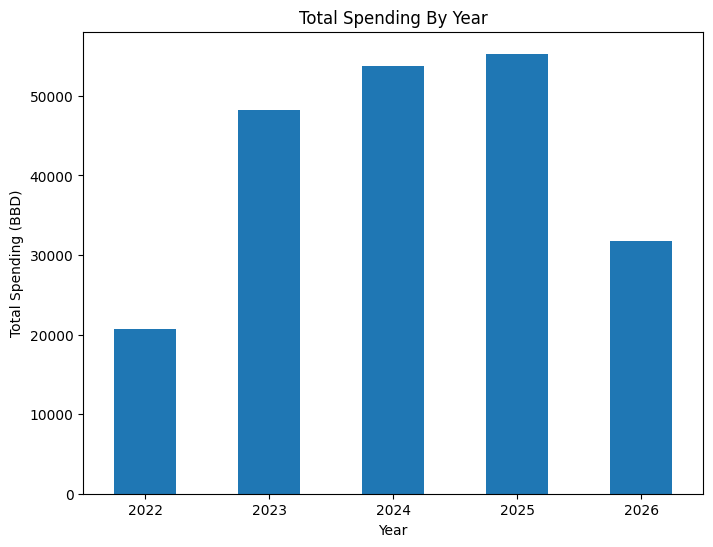

In [174]:
df_q1.plot.bar(figsize=(8,6),
               legend=False,
               title='Total Spending By Year',
               ylabel='Total Spending (BBD)',
               rot=0
               )
plt.show()

#### __Q2. Which year have I earned the most?__

In [175]:
df_q2 = df[df['Type']=='Credits'][['Year','Credits']].groupby('Year').sum()
print(df_q2)
print(f"\nMax income: ${df_q2['Credits'].max():,.2f}, Year: {df_q2['Credits'].idxmax()}")


       Credits
Year          
2022  19146.77
2023  49876.12
2024  53340.20
2025  56199.27
2026  33740.91

Max income: $56,199.27, Year: 2025


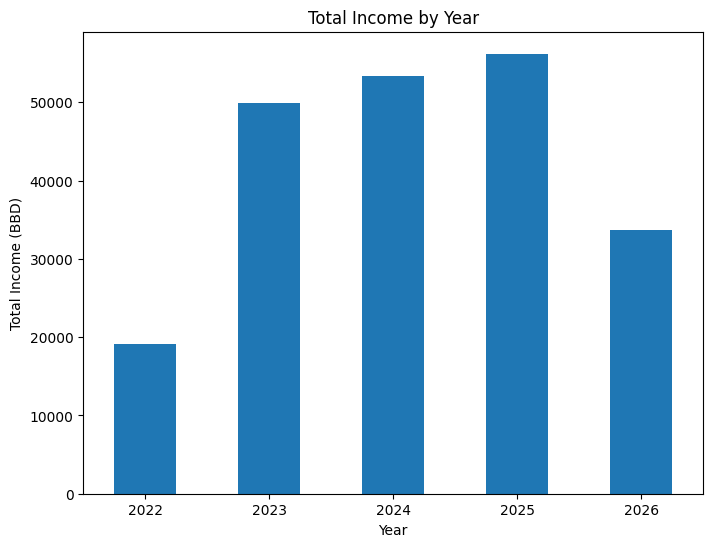

In [176]:
df_q2.plot.bar(figsize=(8,6), 
               legend=False,
               title='Total Income by Year',
               ylabel='Total Income (BBD)',
               rot=0
               )
plt.show()

### __Q3. Yearly Expenses vs Yearly Income__

In [177]:
df_q3 = df_q1.merge(df_q2, left_index=True, right_index=True)
print(df_q3)

print()
print(df_q3.apply(lambda x: 'Spent more this year' if x['Debits'] > x['Credits'] else 'Earned more this year', axis=1))

        Debits   Credits
Year                    
2022  20727.86  19146.77
2023  48199.37  49876.12
2024  53790.74  53340.20
2025  55288.43  56199.27
2026  31730.23  33740.91

Year
2022     Spent more this year
2023    Earned more this year
2024     Spent more this year
2025    Earned more this year
2026    Earned more this year
dtype: object


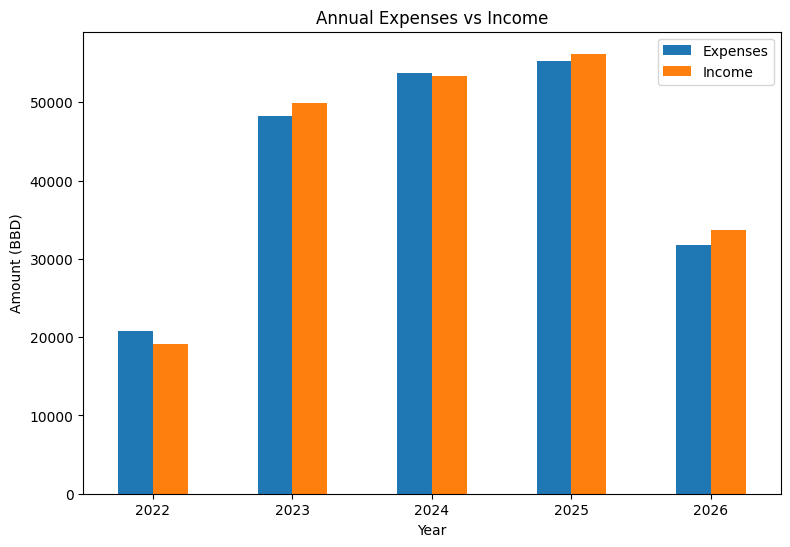

In [178]:
df_q3.plot.bar(figsize=(9,6),
               title='Annual Expenses vs Income',
               ylabel='Amount (BBD)',
               rot=0
               )
plt.legend(['Expenses', 'Income'])
plt.show()

### __Q4. Which months have I spent the most each year?__

In [179]:
df_q4 = df[df['Type']=='Debits'][['FullDate','Debits']].groupby([df['FullDate'].dt.year, df['FullDate'].dt.month])['Debits'].sum()
df_q4.index = df_q4.index.set_names(['Year','Month'])
df_q4

Year  Month
2022  8        4046.65
      9        4245.37
      10       3885.76
      11       3773.95
      12       4776.13
2023  1        4488.25
      2        3808.88
      3        3664.88
      4        3678.16
      5        4328.38
      6        4136.90
      7        3980.99
      8        3926.39
      9        4172.43
      10       4503.42
      11       3847.93
      12       3662.76
2024  1        4329.15
      2        4566.78
      3        4513.44
      4        4448.22
      5        4506.38
      6        4027.84
      7        4418.54
      8        4208.11
      9        4350.84
      10       6058.90
      11       4219.37
      12       4143.17
2025  1        3889.50
      2        5657.90
      3        4507.00
      4        4233.50
      5        4302.13
      6        4699.51
      7        4298.42
      8        4771.12
      9        4389.24
      10       4735.61
      11       4782.45
      12       5022.05
2026  1        4314.16
      2        3873.99

In [180]:
df_q4 = df_q4.reset_index()
df_q4

,Year,Month,Debits
0,2022,8,4046.65
1,2022,9,4245.37
2,2022,10,3885.76
3,2022,11,3773.95
4,2022,12,4776.13
5,2023,1,4488.25
6,2023,2,3808.88
7,2023,3,3664.88
8,2023,4,3678.16
9,2023,5,4328.38


In [181]:
df_q4['Month-Text'] = pd.to_datetime(df_q4["Month"], format="%m").dt.strftime("%b").str.upper()
df_q4

,Year,Month,Debits,Month-Text
0,2022,8,4046.65,AUG
1,2022,9,4245.37,SEPT
2,2022,10,3885.76,OCT
3,2022,11,3773.95,NOV
4,2022,12,4776.13,DEC
5,2023,1,4488.25,JAN
6,2023,2,3808.88,FEB
7,2023,3,3664.88,MAR
8,2023,4,3678.16,APR
9,2023,5,4328.38,MAY


Find index of max spending for each year. Store as Series in a list. Create DataFrame with list where each item in the list is added horizontally/as a column.

In [182]:
rows = []

for year in df_q4['Year'].unique():
    max_index = df_q4[df_q4['Year']==year]['Debits'].idxmax()
    rows.append(df_q4.loc[max_index])

df_q4_bar = pd.concat(rows, axis=1)
df_q4_bar 

,4,14,26,30,46
Year,2022,2023,2024,2025,2026
Month,12,10,10,2,6
Debits,4776.13,4503.42,6058.9,5657.9,5784.04
Month-Text,DEC,OCT,OCT,FEB,JUN


Transpose data and set multi-index for easier plotting.

In [183]:
df_q4_bar = df_q4_bar.T[['Year','Month-Text','Debits']].set_index(['Year','Month-Text'])
df_q4_bar

,,Debits
Year,Month-Text,
2022,DEC,4776.13
2023,OCT,4503.42
2024,OCT,6058.9
2025,FEB,5657.9
2026,JUN,5784.04


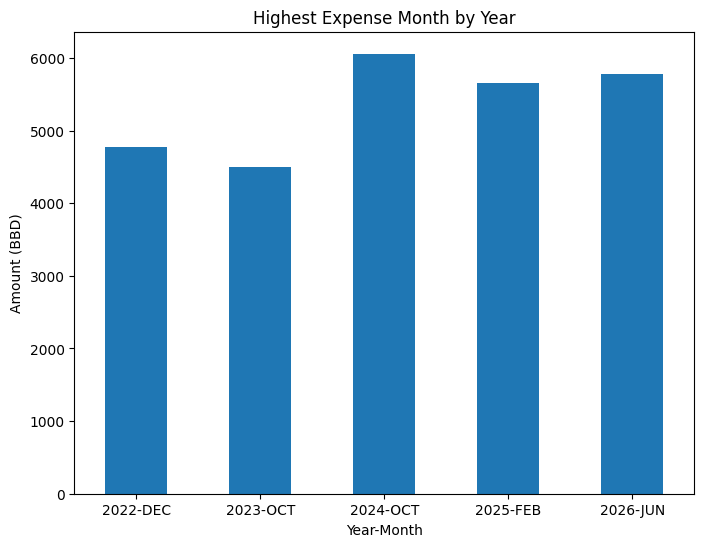

In [184]:
xlabels = [f'{idx[0]}-{idx[1]}'for idx in df_q4_bar.index]

df_q4_bar.plot.bar(legend=False,
                   figsize=(8,6), 
                   title='Highest Expense Month by Year',
                   xlabel='Year-Month',
                   ylabel='Amount (BBD)'
                   )
plt.xticks(ticks=range(0, 5, 1), labels=xlabels, rotation=0)
plt.show()


### __Q5. Which months have I earned the most each year?__

In [185]:
df_q5 = df[df['Type']=='Credits'][['FullDate','Credits']].groupby([df['FullDate'].dt.year, df['FullDate'].dt.month])['Credits'].sum()
df_q5.index = df_q5.index.set_names(['Year','Month'])
df_q5

Year  Month
2022  8        3966.35
      9        3750.00
      10       4050.42
      11       3680.00
      12       3700.00
2023  1        4209.64
      2        4066.79
      3        4272.25
      4        4165.79
      5        4014.17
      6        4112.36
      7        4211.51
      8        4126.07
      9        4304.48
      10       4235.28
      11       4132.50
      12       4025.28
2024  1        4251.97
      2        4278.06
      3        4619.67
      4        4638.95
      5        4150.00
      6        4839.82
      7        4232.19
      8        4733.54
      9        4292.12
      10       4271.68
      11       4674.82
      12       4357.38
2025  1        4796.19
      2        4405.00
      3        4425.00
      4        4567.48
      5        4686.13
      6        4746.73
      7        4704.51
      8        4848.98
      9        4843.77
      10       4661.61
      11       4594.30
      12       4919.57
2026  1        5130.55
      2        4700.00

In [186]:
df_q5 = df_q5.reset_index()
df_q5

,Year,Month,Credits
0,2022,8,3966.35
1,2022,9,3750.00
2,2022,10,4050.42
3,2022,11,3680.00
4,2022,12,3700.00
5,2023,1,4209.64
6,2023,2,4066.79
7,2023,3,4272.25
8,2023,4,4165.79
9,2023,5,4014.17


In [187]:
df_q5['Month-Text'] = pd.to_datetime(df_q5["Month"], format="%m").dt.strftime("%b").str.upper()
df_q5

,Year,Month,Credits,Month-Text
0,2022,8,3966.35,AUG
1,2022,9,3750.00,SEPT
2,2022,10,4050.42,OCT
3,2022,11,3680.00,NOV
4,2022,12,3700.00,DEC
5,2023,1,4209.64,JAN
6,2023,2,4066.79,FEB
7,2023,3,4272.25,MAR
8,2023,4,4165.79,APR
9,2023,5,4014.17,MAY


In [188]:
rows = []

for year in df_q5['Year'].unique():
    max_index = df_q5[df_q5['Year']==year]['Credits'].idxmax()
    rows.append(df_q5.loc[max_index])

df_q5_bar = pd.concat(rows, axis=1)
df_q5_bar 

,2,13,22,40,41
Year,2022,2023,2024,2025,2026
Month,10,9,6,12,1
Credits,4050.42,4304.48,4839.82,4919.57,5130.55
Month-Text,OCT,SEPT,JUN,DEC,JAN


In [189]:
df_q5_bar = df_q5_bar.T[['Year','Month-Text','Credits']].set_index(['Year','Month-Text'])
df_q5_bar

,,Credits
Year,Month-Text,
2022,OCT,4050.42
2023,SEPT,4304.48
2024,JUN,4839.82
2025,DEC,4919.57
2026,JAN,5130.55


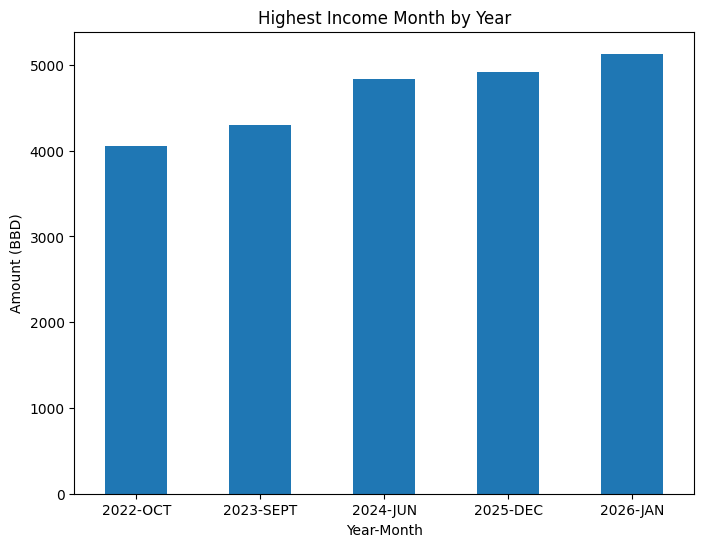

In [190]:
xlabels = [f'{idx[0]}-{idx[1]}'for idx in df_q5_bar.index]

df_q5_bar.plot.bar(legend=False,
                   figsize=(8,6), 
                   title='Highest Income Month by Year',
                   xlabel='Year-Month',
                   ylabel='Amount (BBD)'
                   )
plt.xticks(ticks=range(0, 5, 1), labels=xlabels, rotation=0)
plt.show()


### __Q6. What is the overall money spent?__

In [191]:
overall_spend = df[df['Type']=='Debits']['Debits'].sum()
f'Overall spend: ${overall_spend:,.2f}'

'Overall spend: $209,736.63'

### __Q7. What is the overall money earned?__

In [192]:
overall_income = df[df['Type']=='Credits']['Credits'].sum()
f'Overall income: ${overall_income:,.2f}'

'Overall income: $212,303.27'

### __Q8. Which business/entity have I spent the most money at? (Yearly and Overall)__

#### 8a. Entities where the most money was spent overall

In [193]:
df_q8 = df[df['Type']=='Debits'][['Description_Trim','Debits']].groupby('Description_Trim').sum().sort_values('Debits', ascending=False).head(10)
df_q8

,Debits
Description_Trim,
Rent,61429.81
Massy Stores,21334.70
Barbados Light & Power,9733.81
Trimart,7969.97
SOL,7408.49
Rubis,6934.91
Cost-U-LESS,6533.97
Popular Discounts,6072.40
Amazon,5605.42


In [194]:
f'Most money spent overall: {df_q8.index[0]} - ${df_q8.iloc[0,0]:,}'

'Most money spent overall: Rent - $61,429.81'

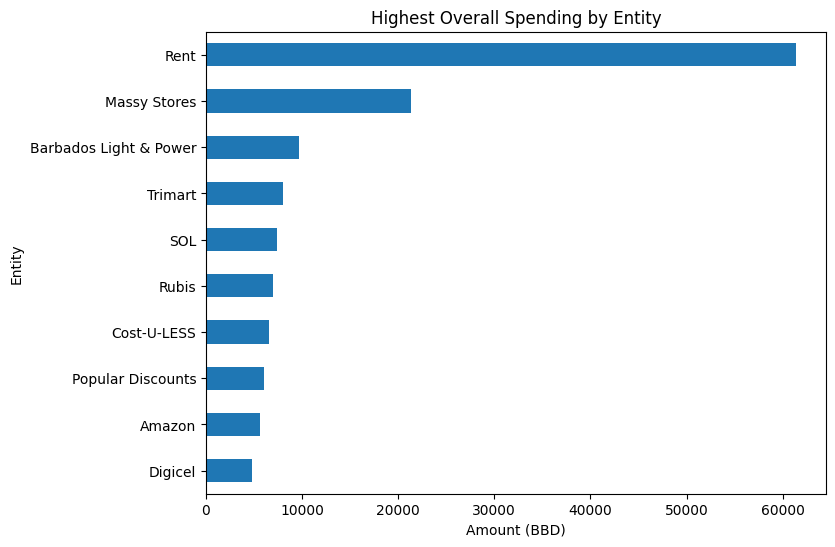

In [195]:
df_q8_descending = df_q8.sort_values('Debits')
df_q8_descending.plot.barh(legend=False,
                           figsize=(8,6),
                           title='Highest Overall Spending by Entity',
                           xlabel='Amount (BBD)',
                           ylabel='Entity'
                           )
plt.show()

#### 8b. Entities where the most money is spent yearly

In [196]:
df_q8_yearly = df[df['Type']=='Debits'][['Year','Description_Trim','Debits']].groupby(['Year','Description_Trim']).sum()
df_q8_yearly

Debits
Year Description_Trim              
2022 Abeds                    33.33
     Amazon                  502.76
     Andre Thompson           36.20
     BWA                     144.58
     Barbados Light & Power  991.94
...                             ...
2026 Uber                    332.30
     Walmart                 150.00
     Worthing Parking         58.28
     Zara                     21.00
     iMart                   130.16

[294 rows x 1 columns]

In [197]:
df_q8_yearly = df_q8_yearly.reset_index()
df_q8_yearly

,Year,Description_Trim,Debits
0,2022,Abeds,33.33
1,2022,Amazon,502.76
2,2022,Andre Thompson,36.20
3,2022,BWA,144.58
4,2022,Barbados Light & Power,991.94
...,...,...,...
289,2026,Uber,332.30
290,2026,Walmart,150.00
291,2026,Worthing Parking,58.28
292,2026,Zara,21.00


In [198]:
rows = []

for year in df_q8_yearly['Year'].unique():
    max_index = df_q8_yearly[df_q8_yearly['Year']==year]['Debits'].idxmax()
    rows.append(df_q8_yearly.loc[max_index])

df_q8_yearly_bar = pd.concat(rows, axis=1)
df_q8_yearly_bar 

,36,95,155,218,280
Year,2022,2023,2024,2025,2026
Description_Trim,Rent,Rent,Rent,Rent,Rent
Debits,6011.31,14361.27,16058.32,15819.84,9179.07


In [199]:
df_q8_yearly_bar = df_q8_yearly_bar.T.set_index(['Year','Description_Trim'])
df_q8_yearly_bar['Debits'] = pd.to_numeric(df_q8_yearly_bar['Debits'])
df_q8_yearly_bar

,,Debits
Year,Description_Trim,
2022,Rent,6011.31
2023,Rent,14361.27
2024,Rent,16058.32
2025,Rent,15819.84
2026,Rent,9179.07


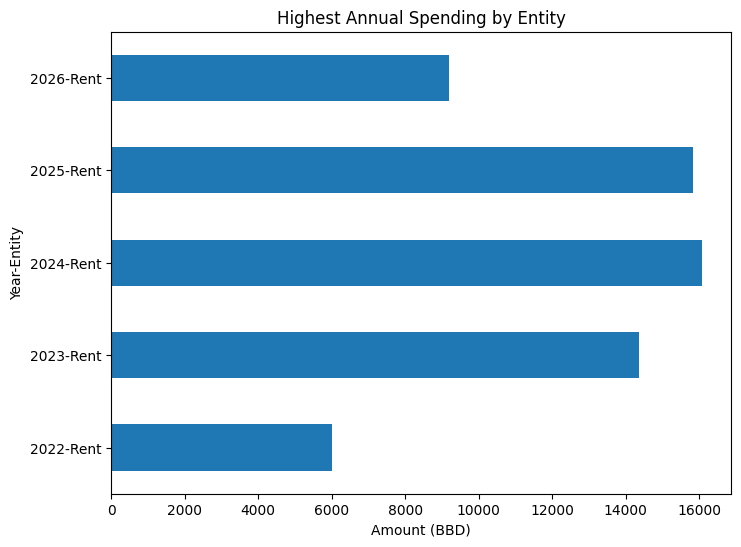

In [200]:
df_q8_yearly_bar.plot.barh(legend=False, figsize=(8,6), 
                           title='Highest Annual Spending by Entity')
xlabels = [f'{x[0]}-{x[1]}' for x in df_q8_yearly_bar.index]
plt.xlabel('Amount (BBD)')
plt.ylabel('Year-Entity')
plt.yticks(range(5) ,xlabels)
plt.show()

### __Q9. How much have I spent in FXF?__

In [201]:
df_q9 = df[df['Description_Trim']=='FXF'][['Description_Trim','Debits']].groupby('Description_Trim').sum()
df_q9

,Debits
Description_Trim,
FXF,368.25


In [202]:
f'Total FXF expenses: ${df_q9.iloc[0,0]}'

'Total FXF expenses: $368.25'

### __Q10. Spending Over Time__

In [203]:
df_q10 = df[df['Type']=='Debits'][['FullDate','Debits']].groupby([df['FullDate'].dt.year, df['FullDate'].dt.month])['Debits'].sum()
df_q10.index = df_q10.index.set_names(['Year','Month'])
df_q10

Year  Month
2022  8        4046.65
      9        4245.37
      10       3885.76
      11       3773.95
      12       4776.13
2023  1        4488.25
      2        3808.88
      3        3664.88
      4        3678.16
      5        4328.38
      6        4136.90
      7        3980.99
      8        3926.39
      9        4172.43
      10       4503.42
      11       3847.93
      12       3662.76
2024  1        4329.15
      2        4566.78
      3        4513.44
      4        4448.22
      5        4506.38
      6        4027.84
      7        4418.54
      8        4208.11
      9        4350.84
      10       6058.90
      11       4219.37
      12       4143.17
2025  1        3889.50
      2        5657.90
      3        4507.00
      4        4233.50
      5        4302.13
      6        4699.51
      7        4298.42
      8        4771.12
      9        4389.24
      10       4735.61
      11       4782.45
      12       5022.05
2026  1        4314.16
      2        3873.99

In [204]:
df_q10 = df_q10.reset_index()
df_q10['Month-Text'] = pd.to_datetime(df_q10['Month'], format="%m").dt.strftime("%b").str.upper()
df_q10 

,Year,Month,Debits,Month-Text
0,2022,8,4046.65,AUG
1,2022,9,4245.37,SEPT
2,2022,10,3885.76,OCT
3,2022,11,3773.95,NOV
4,2022,12,4776.13,DEC
5,2023,1,4488.25,JAN
6,2023,2,3808.88,FEB
7,2023,3,3664.88,MAR
8,2023,4,3678.16,APR
9,2023,5,4328.38,MAY


In [205]:
df_q10 = df_q10[['Year','Month-Text','Debits']].set_index(['Year','Month-Text'])
df_q10

Debits
Year Month-Text         
2022 AUG         4046.65
     SEPT        4245.37
     OCT         3885.76
     NOV         3773.95
     DEC         4776.13
2023 JAN         4488.25
     FEB         3808.88
     MAR         3664.88
     APR         3678.16
     MAY         4328.38
     JUN         4136.90
     JUL         3980.99
     AUG         3926.39
     SEPT        4172.43
     OCT         4503.42
     NOV         3847.93
     DEC         3662.76
2024 JAN         4329.15
     FEB         4566.78
     MAR         4513.44
     APR         4448.22
     MAY         4506.38
     JUN         4027.84
     JUL         4418.54
     AUG         4208.11
     SEPT        4350.84
     OCT         6058.90
     NOV         4219.37
     DEC         4143.17
2025 JAN         3889.50
     FEB         5657.90
     MAR         4507.00
     APR         4233.50
     MAY         4302.13
     JUN         4699.51
     JUL         4298.42
     AUG         4771.12
     SEPT        4389.24
     OCT         4735.61
     NOV         4782.45
     DEC         5022.05
2026 JAN         4314.16
     FEB         3873.99
     MAR         4130.20
     APR         3997.10
     MAY         5124.67
     JUN         5784.04
     JUL         4506.07

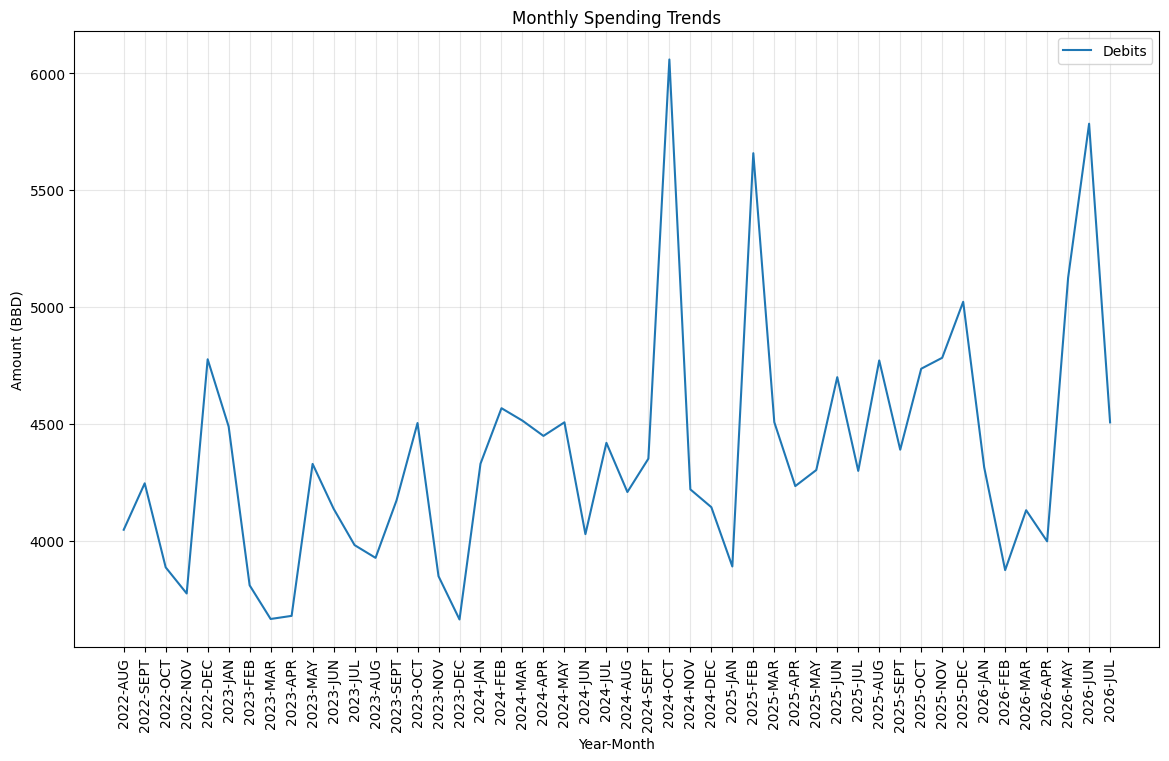

In [206]:
xlabels = [f'{x[0]}-{x[1]}' for x in df_q10.index]

df_q10.plot.line(figsize=(14,8),
                 title='Monthly Spending Trends',
                 ylabel='Amount (BBD)',
                 xlabel='Year-Month'
                 )

plt.grid(alpha=0.3)
plt.xticks(range(0,48,1), xlabels, rotation=90)
plt.show()

### __Q11. Earning Over Time__

In [207]:
df_q11 = df[df['Type']=='Credits'][['FullDate','Credits']].groupby([df['FullDate'].dt.year, df['FullDate'].dt.month])['Credits'].sum()
df_q11.index = df_q11.index.set_names(['Year','Month'])
df_q11

Year  Month
2022  8        3966.35
      9        3750.00
      10       4050.42
      11       3680.00
      12       3700.00
2023  1        4209.64
      2        4066.79
      3        4272.25
      4        4165.79
      5        4014.17
      6        4112.36
      7        4211.51
      8        4126.07
      9        4304.48
      10       4235.28
      11       4132.50
      12       4025.28
2024  1        4251.97
      2        4278.06
      3        4619.67
      4        4638.95
      5        4150.00
      6        4839.82
      7        4232.19
      8        4733.54
      9        4292.12
      10       4271.68
      11       4674.82
      12       4357.38
2025  1        4796.19
      2        4405.00
      3        4425.00
      4        4567.48
      5        4686.13
      6        4746.73
      7        4704.51
      8        4848.98
      9        4843.77
      10       4661.61
      11       4594.30
      12       4919.57
2026  1        5130.55
      2        4700.00

In [208]:
df_q11 = df_q11.reset_index()
df_q11['Month-Text'] = pd.to_datetime(df_q11['Month'], format="%m").dt.strftime("%b").str.upper()
df_q11 

,Year,Month,Credits,Month-Text
0,2022,8,3966.35,AUG
1,2022,9,3750.00,SEPT
2,2022,10,4050.42,OCT
3,2022,11,3680.00,NOV
4,2022,12,3700.00,DEC
5,2023,1,4209.64,JAN
6,2023,2,4066.79,FEB
7,2023,3,4272.25,MAR
8,2023,4,4165.79,APR
9,2023,5,4014.17,MAY


In [209]:
df_q11 = df_q11[['Year','Month-Text','Credits']].set_index(['Year','Month-Text'])
df_q11

Credits
Year Month-Text         
2022 AUG         3966.35
     SEPT        3750.00
     OCT         4050.42
     NOV         3680.00
     DEC         3700.00
2023 JAN         4209.64
     FEB         4066.79
     MAR         4272.25
     APR         4165.79
     MAY         4014.17
     JUN         4112.36
     JUL         4211.51
     AUG         4126.07
     SEPT        4304.48
     OCT         4235.28
     NOV         4132.50
     DEC         4025.28
2024 JAN         4251.97
     FEB         4278.06
     MAR         4619.67
     APR         4638.95
     MAY         4150.00
     JUN         4839.82
     JUL         4232.19
     AUG         4733.54
     SEPT        4292.12
     OCT         4271.68
     NOV         4674.82
     DEC         4357.38
2025 JAN         4796.19
     FEB         4405.00
     MAR         4425.00
     APR         4567.48
     MAY         4686.13
     JUN         4746.73
     JUL         4704.51
     AUG         4848.98
     SEPT        4843.77
     OCT         4661.61
     NOV         4594.30
     DEC         4919.57
2026 JAN         5130.55
     FEB         4700.00
     MAR         4747.52
     APR         4766.40
     MAY         4776.18
     JUN         4791.66
     JUL         4828.60

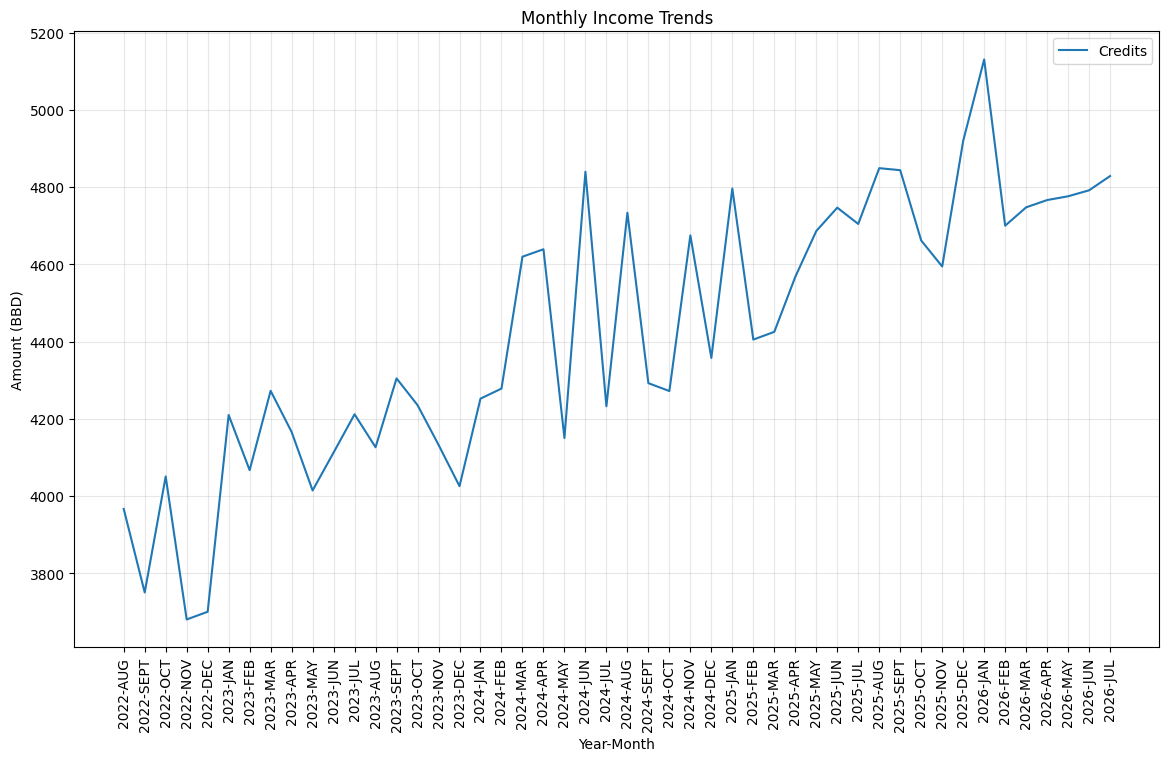

In [210]:
xlabels = [f'{x[0]}-{x[1]}' for x in df_q11.index]

df_q11.plot.line(figsize=(14,8),
                 title='Monthly Income Trends',
                 ylabel='Amount (BBD)',
                 xlabel='Year-Month'
                 )

plt.grid(alpha=0.3)
plt.xticks(range(0,48,1), xlabels, rotation=90)
plt.show()

## Dashboard

Plotly and Dash are used to render the dashboard. The HTML is styled with a local stylesheet for simplicity.

All the dataframes were created already to answer each business question. These dataframes are reused with Plotly to create the visuals.

In [211]:
app = Dash()

radio_buttons_list = ['Expenses','Income']
indicators_height = 200
newlabelnames = {'Debits':radio_buttons_list[0], 'Credits':radio_buttons_list [1]}

# Figure for Business Question 3
fig_q3 = px.bar(
                df_q3,
                x=df_q3.index,
                y=['Debits','Credits'],
                barmode='group',
                labels={'x':'Year', 'value':'Amount (BBD)','variable':'Transaction Type'}
)

fig_q3.update_layout(title_text='Annual Expenses vs Income',
                     yaxis=dict(tickformat='$,'))

fig_q3.for_each_trace(lambda x: x.update(name = newlabelnames[x.name],
                                         legendgroup = newlabelnames[x.name],
                                         hovertemplate = x.hovertemplate.replace(x.name, newlabelnames[x.name])
                                         ))

# Figure for Business Question 6
fig_q6 = go.Figure(go.Indicator(
    value=overall_spend,
    mode='number',
    number={'prefix':'$'},
    title={'text':'Total Expenses'}
))

fig_q6.update_layout(margin=dict(l=0, r=0, t=0, b=0), height=indicators_height)

# Figure for Business Question 7
fig_q7 = go.Figure(go.Indicator(
    value=overall_income,
    mode='number',
    number={'prefix':'$'},
    title={'text':'Total Income'}
))

fig_q7.update_layout(margin=dict(l=0, r=0, t=0, b=0), height=indicators_height)

# Figure for Business Question 8 Part 1
fig_q8a = px.bar(
    df_q8_descending,
    x='Debits',
    y=df_q8_descending.index,
    labels={'Debits':'Amount (BBD)', 'Description_Trim':'Entity'}
)

fig_q8a.update_layout(title_text='Highest Overall Spending by Entity',
                      xaxis=dict(tickformat='$,'))

# Figure for Business Question 8 Part 2
fig_q8b = px.bar(
    df_q8_yearly_bar,
    x='Debits',
    y=[f'{x[0]}-{x[1]}' for x in df_q8_yearly_bar.index],
    labels={'Debits':'Amount (BBD)','y':'Year-Entity'}
)

fig_q8b.update_layout(title_text='Highest Annual Spending by Entity',
                      xaxis=dict(tickformat='$,'))

# Figure for Business Question 9
fig_q9 = go.Figure(go.Indicator(
    value=df_q9.iloc[0,0],
    mode='number',
    number={'prefix':'$'},
    title={'text':'Total FXF Expenses'}
))

fig_q9.update_layout(margin=dict(l=0, r=0, t=0, b=0), height=indicators_height)

# Figure for Business Question 10 and 11 (figures merged)
df_q10_q11 = df_q10.merge(df_q11, left_index=True, right_index=True)

fig_q10_q11 = px.line(
    df_q10_q11,
    x = [f'{x[0]}-{x[1]}' for x in df_q10_q11.index],
    y =['Debits','Credits'],
    labels={'value':'Amount (BBD)', 'x':'Year-Month', 'variable':'Transaction Type'}
)

fig_q10_q11.update_layout(title_text=f'Monthly Expenses & Income Trends',
                          yaxis=dict(tickformat='$,'))

fig_q10_q11.for_each_trace(lambda x: x.update(name = newlabelnames[x.name],
                                         legendgroup = newlabelnames[x.name],
                                         hovertemplate = x.hovertemplate.replace(x.name, newlabelnames[x.name])
                                         ))

app.layout = html.Div(
    [
        html.Div(
            html.H1('Personal Banking Financial Analysis - Synthetic Data')
        ),
        dcc.Tabs([
            dcc.Tab([
                html.Div([
                            html.Br(),
                            dcc.Graph(figure=fig_q6, className='three-col-grid'),
                            dcc.Graph(figure=fig_q7, className='three-col-grid'),
                            dcc.Graph(figure=fig_q9, className='three-col-grid')
                        ]),
                        html.Br(),
                        html.Div([
                            dcc.Graph(figure=fig_q3)
                        ]),
                        html.Br(),
                        html.Div(
                            dcc.Graph(figure=fig_q10_q11)
                        ),
                        html.Br(),
                        html.Div([
                            dcc.Graph(figure=fig_q8a,
                                      className='two-col-grid'),
                            dcc.Graph(figure=fig_q8b,
                                      className='two-col-grid')
                        ])
                        
                ], label='Overall Summary', className='tab-text'),
            dcc.Tab([
                html.Div([
                            html.Br(),
                            html.Br(),
                            html.Label('Select a transaction type:',
                                    htmlFor='type-selection',
                                    className='label-text'
                                    ),
                            dcc.RadioItems(options=radio_buttons_list,
                                        value=radio_buttons_list[0],
                                        id='type-selection',
                                        inline=True,
                                        className='radio-text'
                                        )
                        ]),
                        html.Br(),
                        html.Div([
                            dcc.Graph(id='years-spending-earning',
                                      className='two-col-grid'
                                    ),
                            dcc.Graph(id='months-spending-earning',
                                      className='two-col-grid'
                                    )
                        ])
            ], label='Transaction Analysis', className='tab-text'),
        ])

        
    ],
    className='container'
)

# Figures for Business Question 1 and 2
@callback(
    Output(component_id='years-spending-earning',component_property='figure'),
    Input(component_id='type-selection', component_property='value')
)
def update_years_spending_earning(val):
    if val == 'Expenses':
        df_q1_px = df_q1.reset_index()
        fig = px.bar(df_q1_px, x='Year', y='Debits',
                     labels={'Debits':'Amount (BBD)'})
        fig.update_layout(title_text=f'Total {val} by Year',
                          yaxis=dict(tickformat='$,'))
        return fig
    
    elif val == 'Income':
        df_q2_px = df_q2.reset_index()
        fig = px.bar(df_q2_px, x='Year', y='Credits',
                     labels={'Credits':'Amount (BBD)'})
        fig.update_layout(title_text=f'Total {val} by Year',
                          yaxis=dict(tickformat='$,'))
        return fig

# Figures for Business Question 4 and 5
@callback(
    Output(component_id='months-spending-earning',component_property='figure'),
    Input(component_id='type-selection', component_property='value')
)
def update_months_spending_earning(val):
    if val == 'Expenses':
        fig = px.bar(df_q4_bar,
                      x=[f'{x[0]}-{x[1]}' for x in df_q4_bar.index],
                      y='Debits',
                      labels={'Debits':'Amount (BBD)', 'x':'Year-Month'})
        fig.update_layout(title_text=f'Highest {val} Month by Year',
                          yaxis=dict(tickformat='$,'))
        return fig
    
    elif val == 'Income':
        fig = px.bar(df_q5_bar,
                      x=[f'{x[0]}-{x[1]}' for x in df_q5_bar.index],
                      y='Credits',
                      labels={'Credits':'Amount (BBD)', 'x':'Year-Month'})
        fig.update_layout(title_text=f'Highest {val} Month by Year',
                          yaxis=dict(tickformat='$,'))
        return fig
    
if __name__ == '__main__':
    app.run(debug=True, jupyter_mode='external')

Dash app running on http://127.0.0.1:8050/
